# 3 · Neuroscience plots  *(45 min)*

The plots you'll make most often, with **your style from notebook 2** already applied. Each section has an
example to run, then ✏️ **Your turn**: plot something yourself in the empty cell below it.

Changed `my_style.mplstyle`? Save it, re-run the setup cell, then re-run your plot.

In [ ]:
# Google Colab only: download the course data. On your own computer this cell does nothing.
import os, sys, urllib.request

REPO = "https://raw.githubusercontent.com/ChantalNaumann/tutorials/main/"
if "google.colab" in sys.modules:
    for f in ["neurodata.py", "images/anatomy.png"]:
        if not os.path.exists(f):
            os.makedirs(os.path.dirname(f) or ".", exist_ok=True)
            urllib.request.urlretrieve(REPO + f, f)

    # Your style file from notebook 2: upload the copy you downloaded at the end of it
    if not os.path.exists("my_style.mplstyle"):
        from google.colab import files
        print("Upload the my_style.mplstyle you downloaded at the end of notebook 2.")
        print("Don't have it? Click Cancel to use a ready-made style instead.")
        try:
            uploaded = files.upload()
        except Exception:
            uploaded = {}
        if uploaded:   # save it as my_style.mplstyle, whatever the browser called it
            with open("my_style.mplstyle", "wb") as out:
                out.write(next(iter(uploaded.values())))
        else:
            urllib.request.urlretrieve(REPO + "minimal.mplstyle", "my_style.mplstyle")

In [22]:
import numpy as np
import matplotlib.pyplot as plt

import neurodata

plt.style.use(["default", "my_style.mplstyle"])   # your style file from notebook 2

Duplicate key in file 'my_style.mplstyle', line 52 ('grid.linewidth : 0.5')


## 1. Membrane potential

A neuron gets a current step from 0.2 to 0.8 s and fires. Two panels share the time axis: with `sharex=True`,
zooming one zooms both. `height_ratios` makes the current panel smaller.

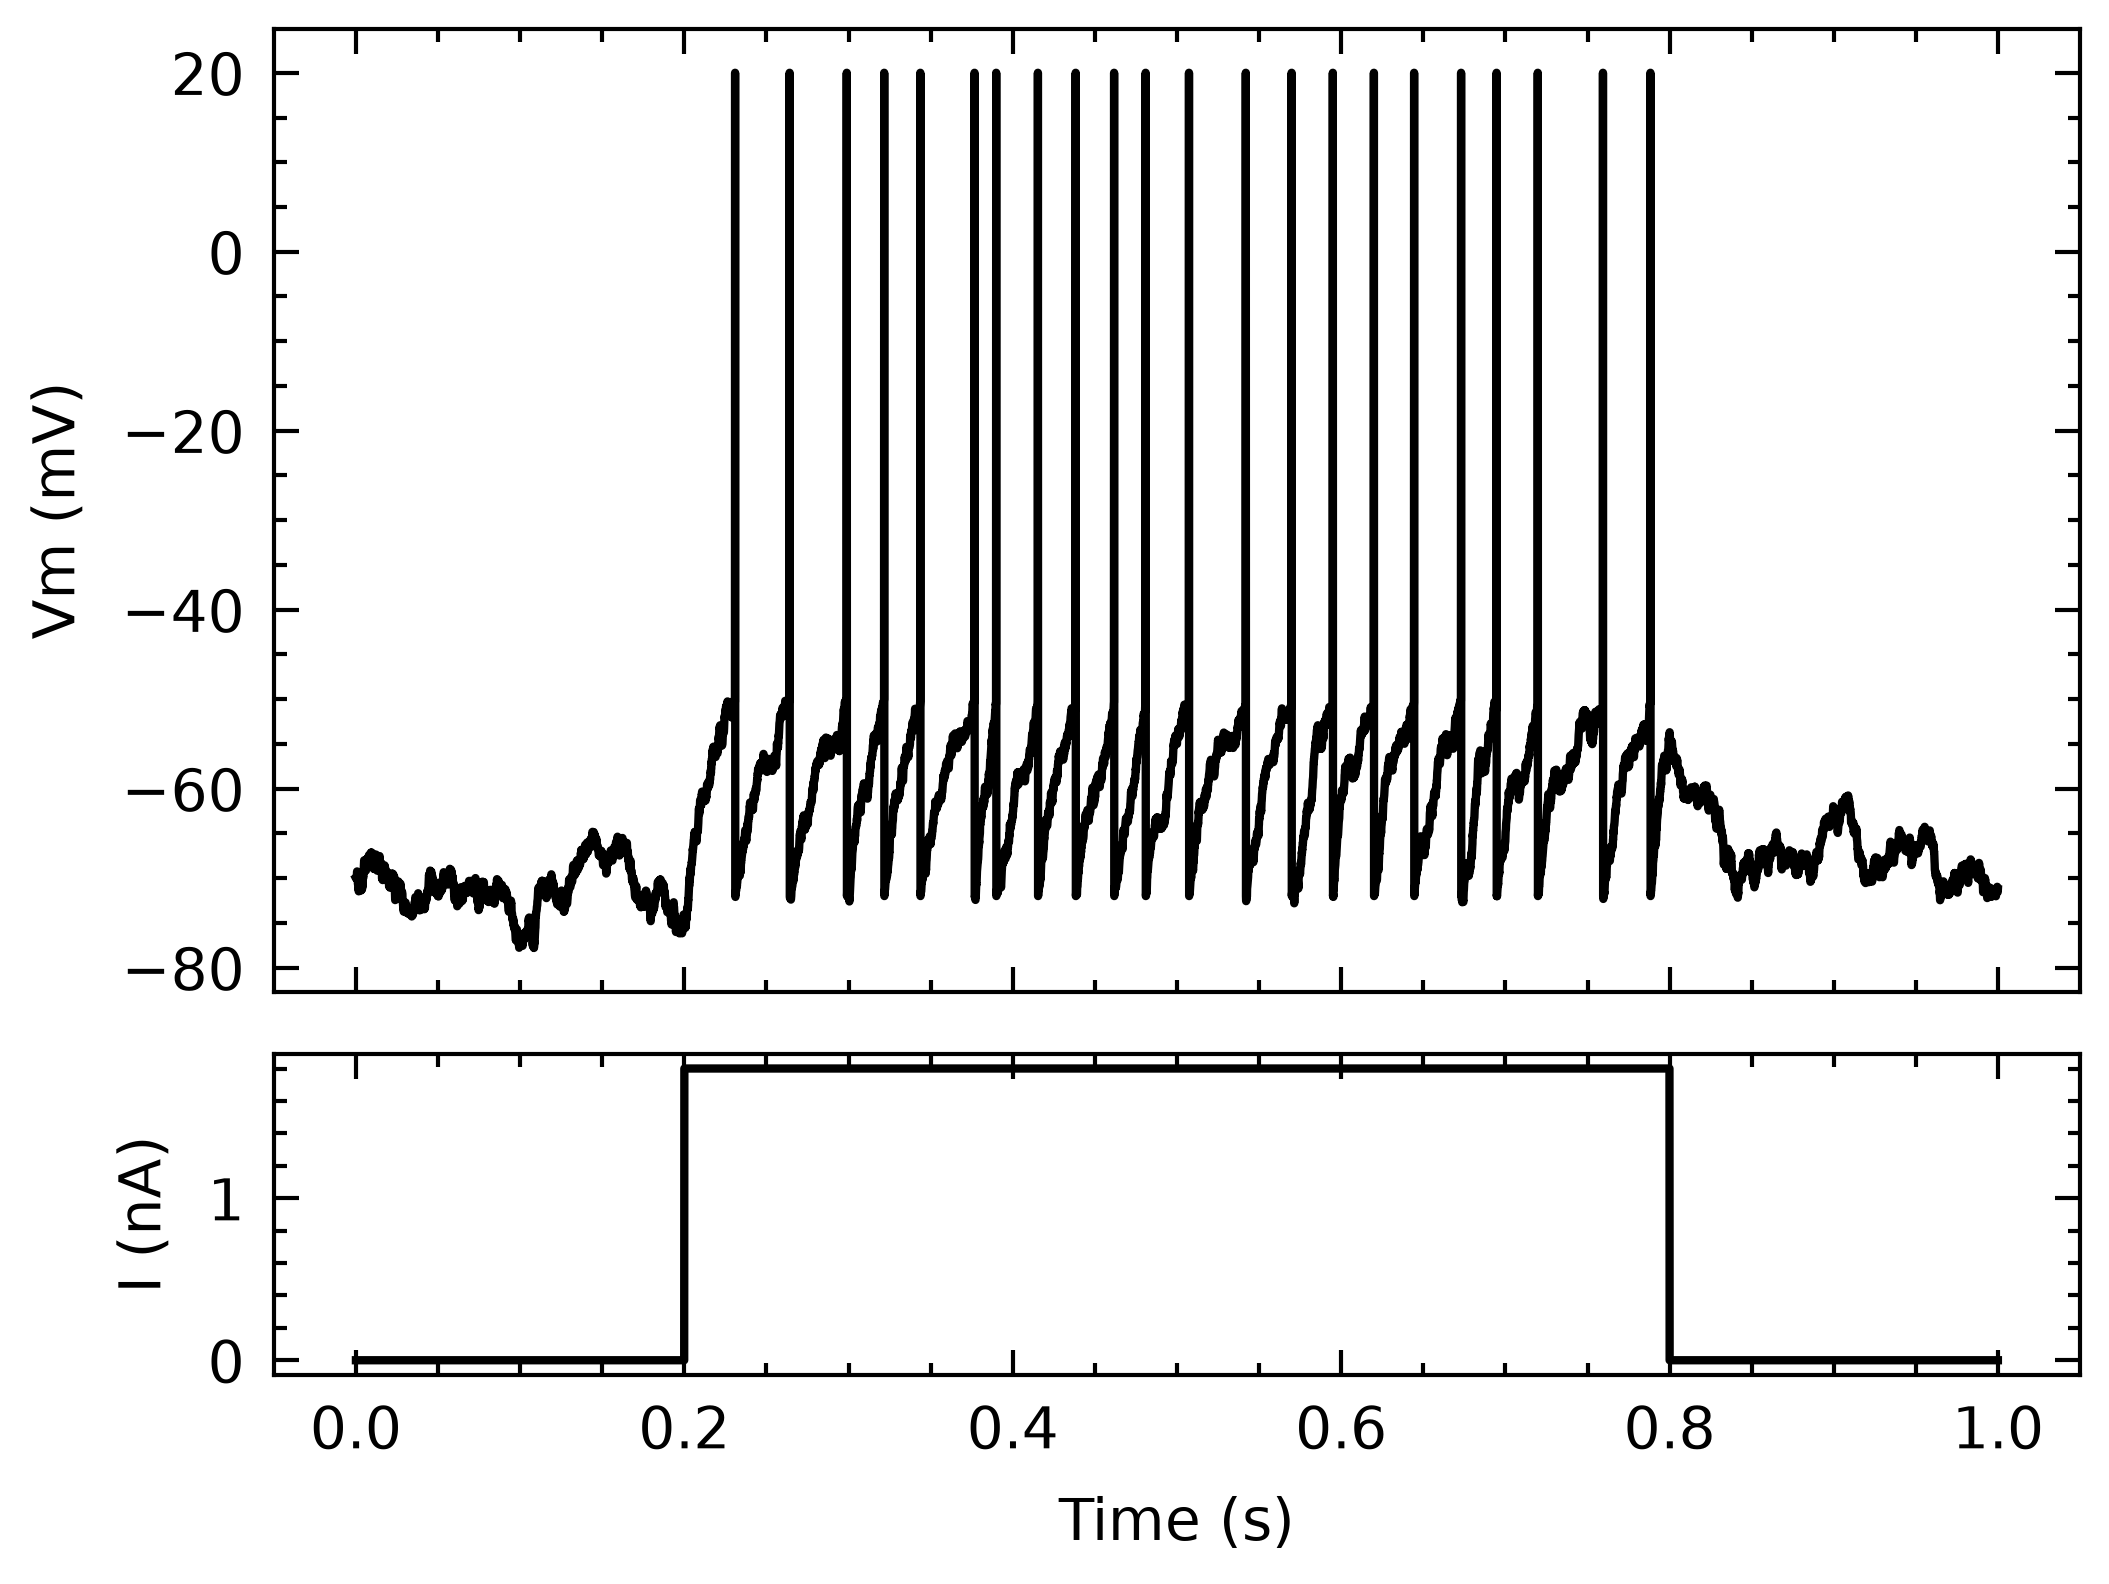

In [35]:
t, v, current, spikes = neurodata.membrane_potential()

fig, (ax_v, ax_i) = plt.subplots(2, 1, sharex=True, height_ratios=[3, 1])
ax_v.plot(t, v)
ax_v.set(ylabel="Vm (mV)")
ax_i.plot(t, current)
ax_i.set(xlabel="Time (s)", ylabel="I (nA)")
plt.show()

✏️ **Your turn**
1. Draw the spike threshold (−50 mV) as a dashed grey line: `ax_v.axhline(-50, color="0.6", linestyle="--")`
2. Zoom in on the first three spikes with `ax_v.set_xlim(start, end)`. `spikes` holds the spike times in seconds.

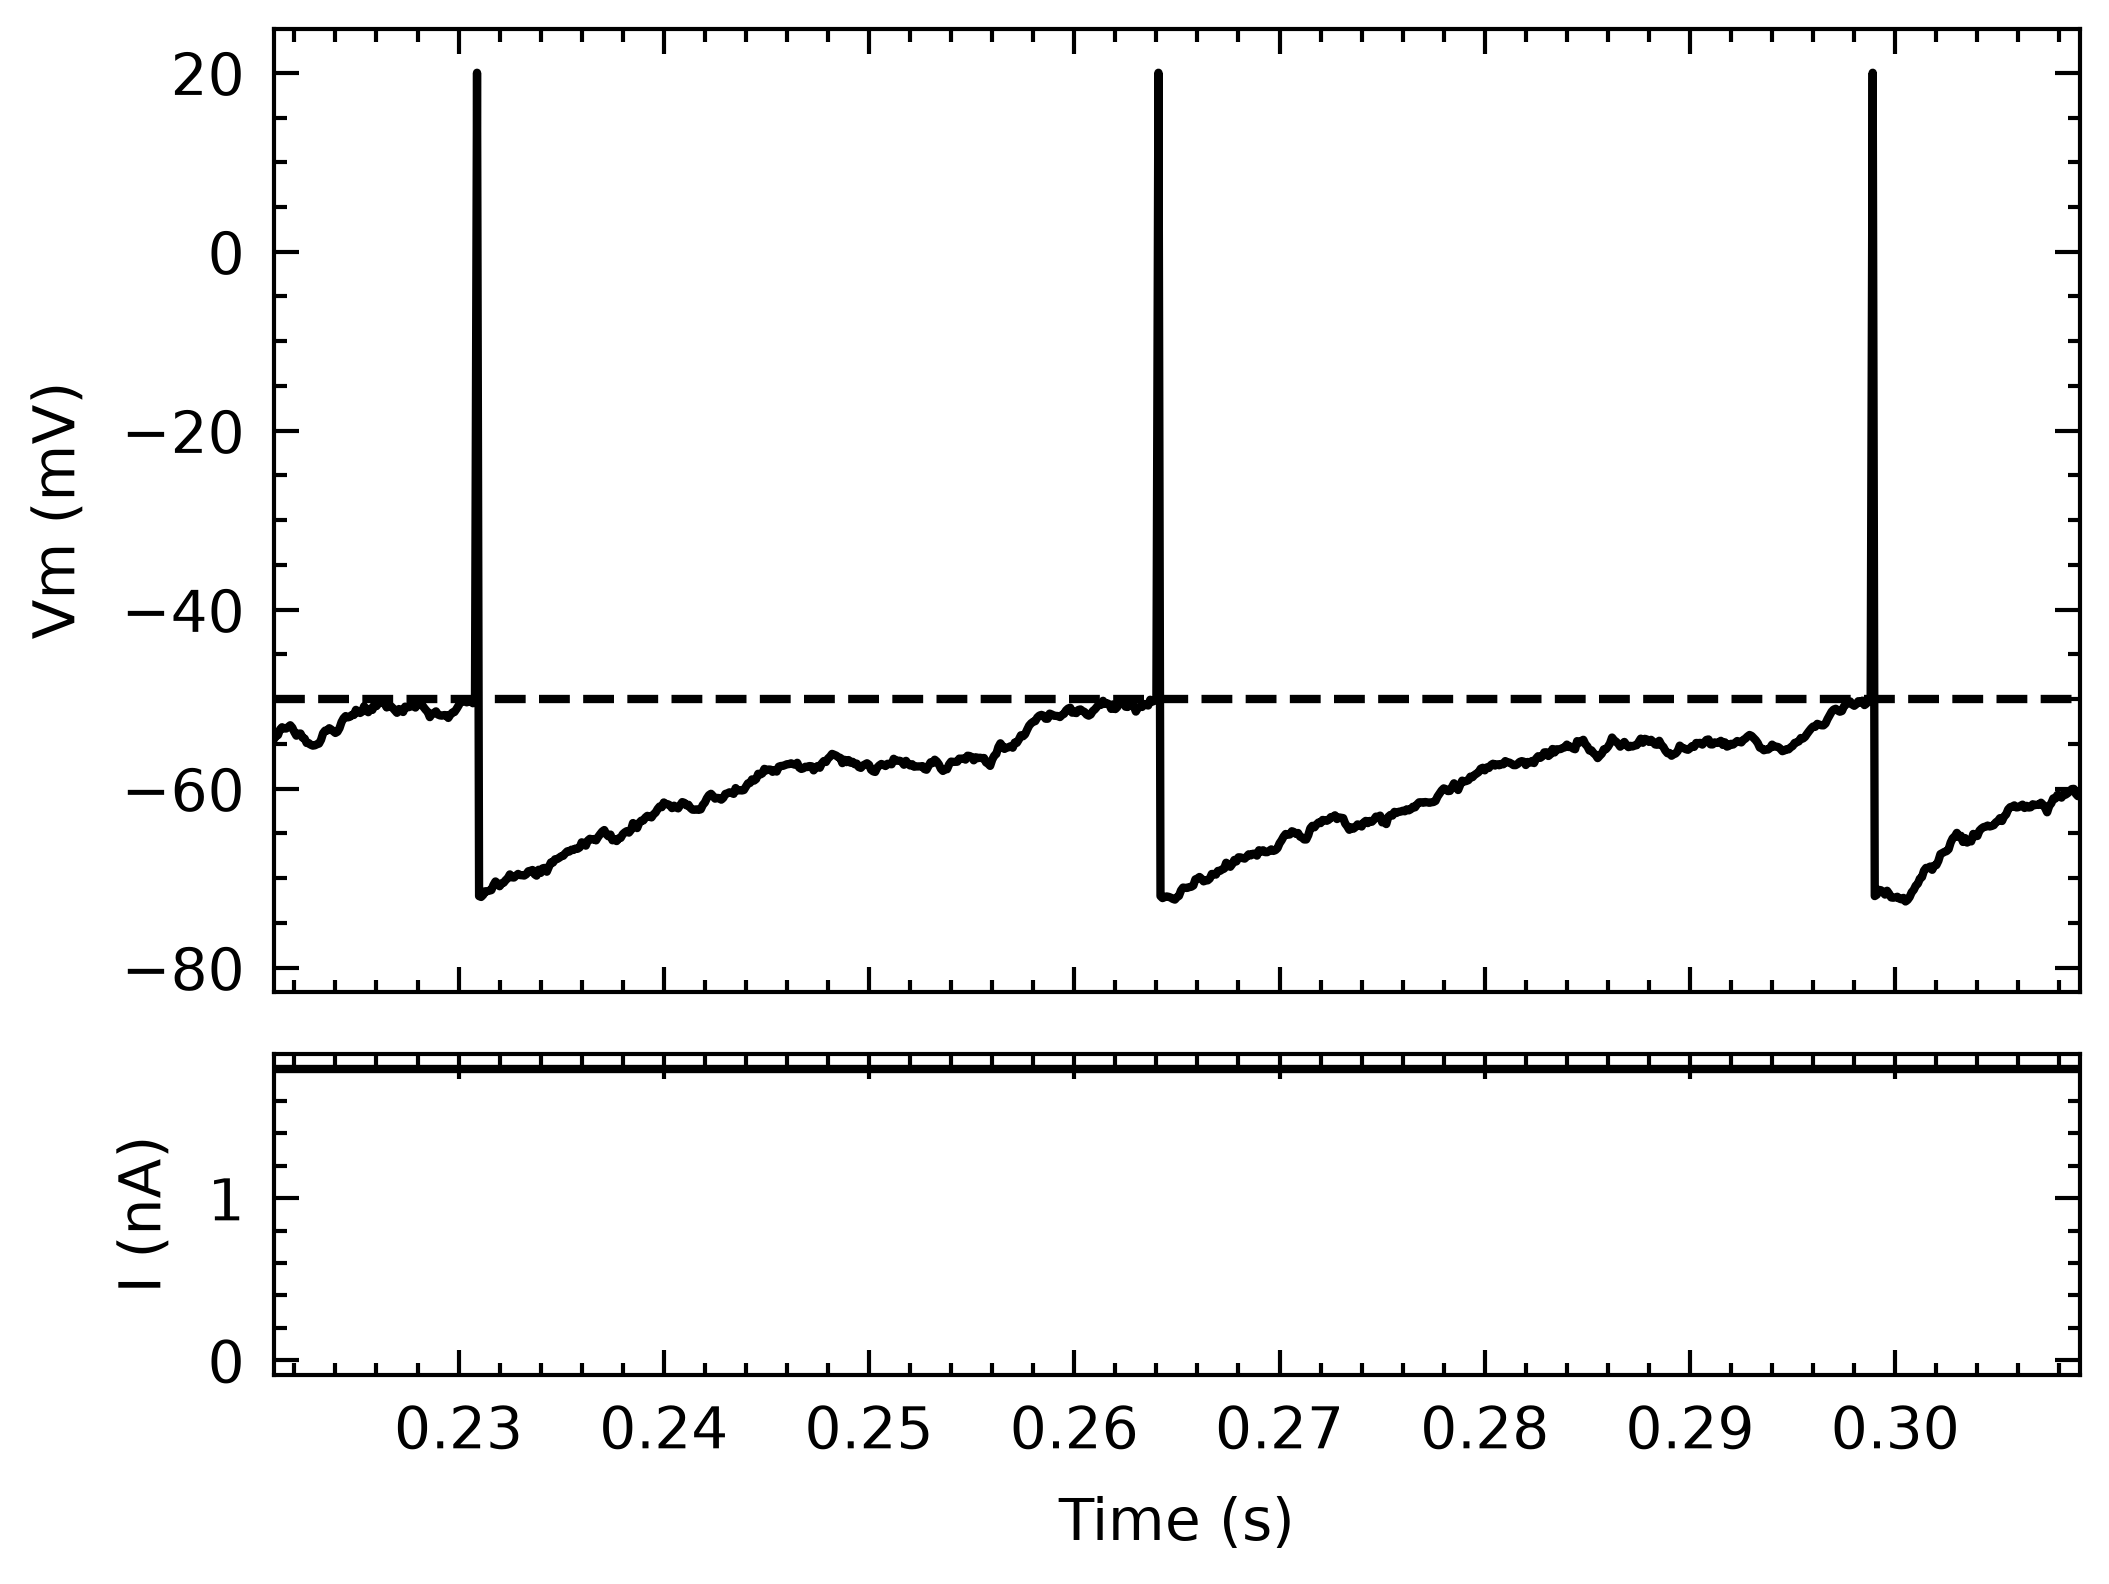

## 2. Spike raster

`ax.eventplot` draws one row of ticks per trial. The stimulus was on from 0.5 to 1.5 s; `axvspan` shades it.

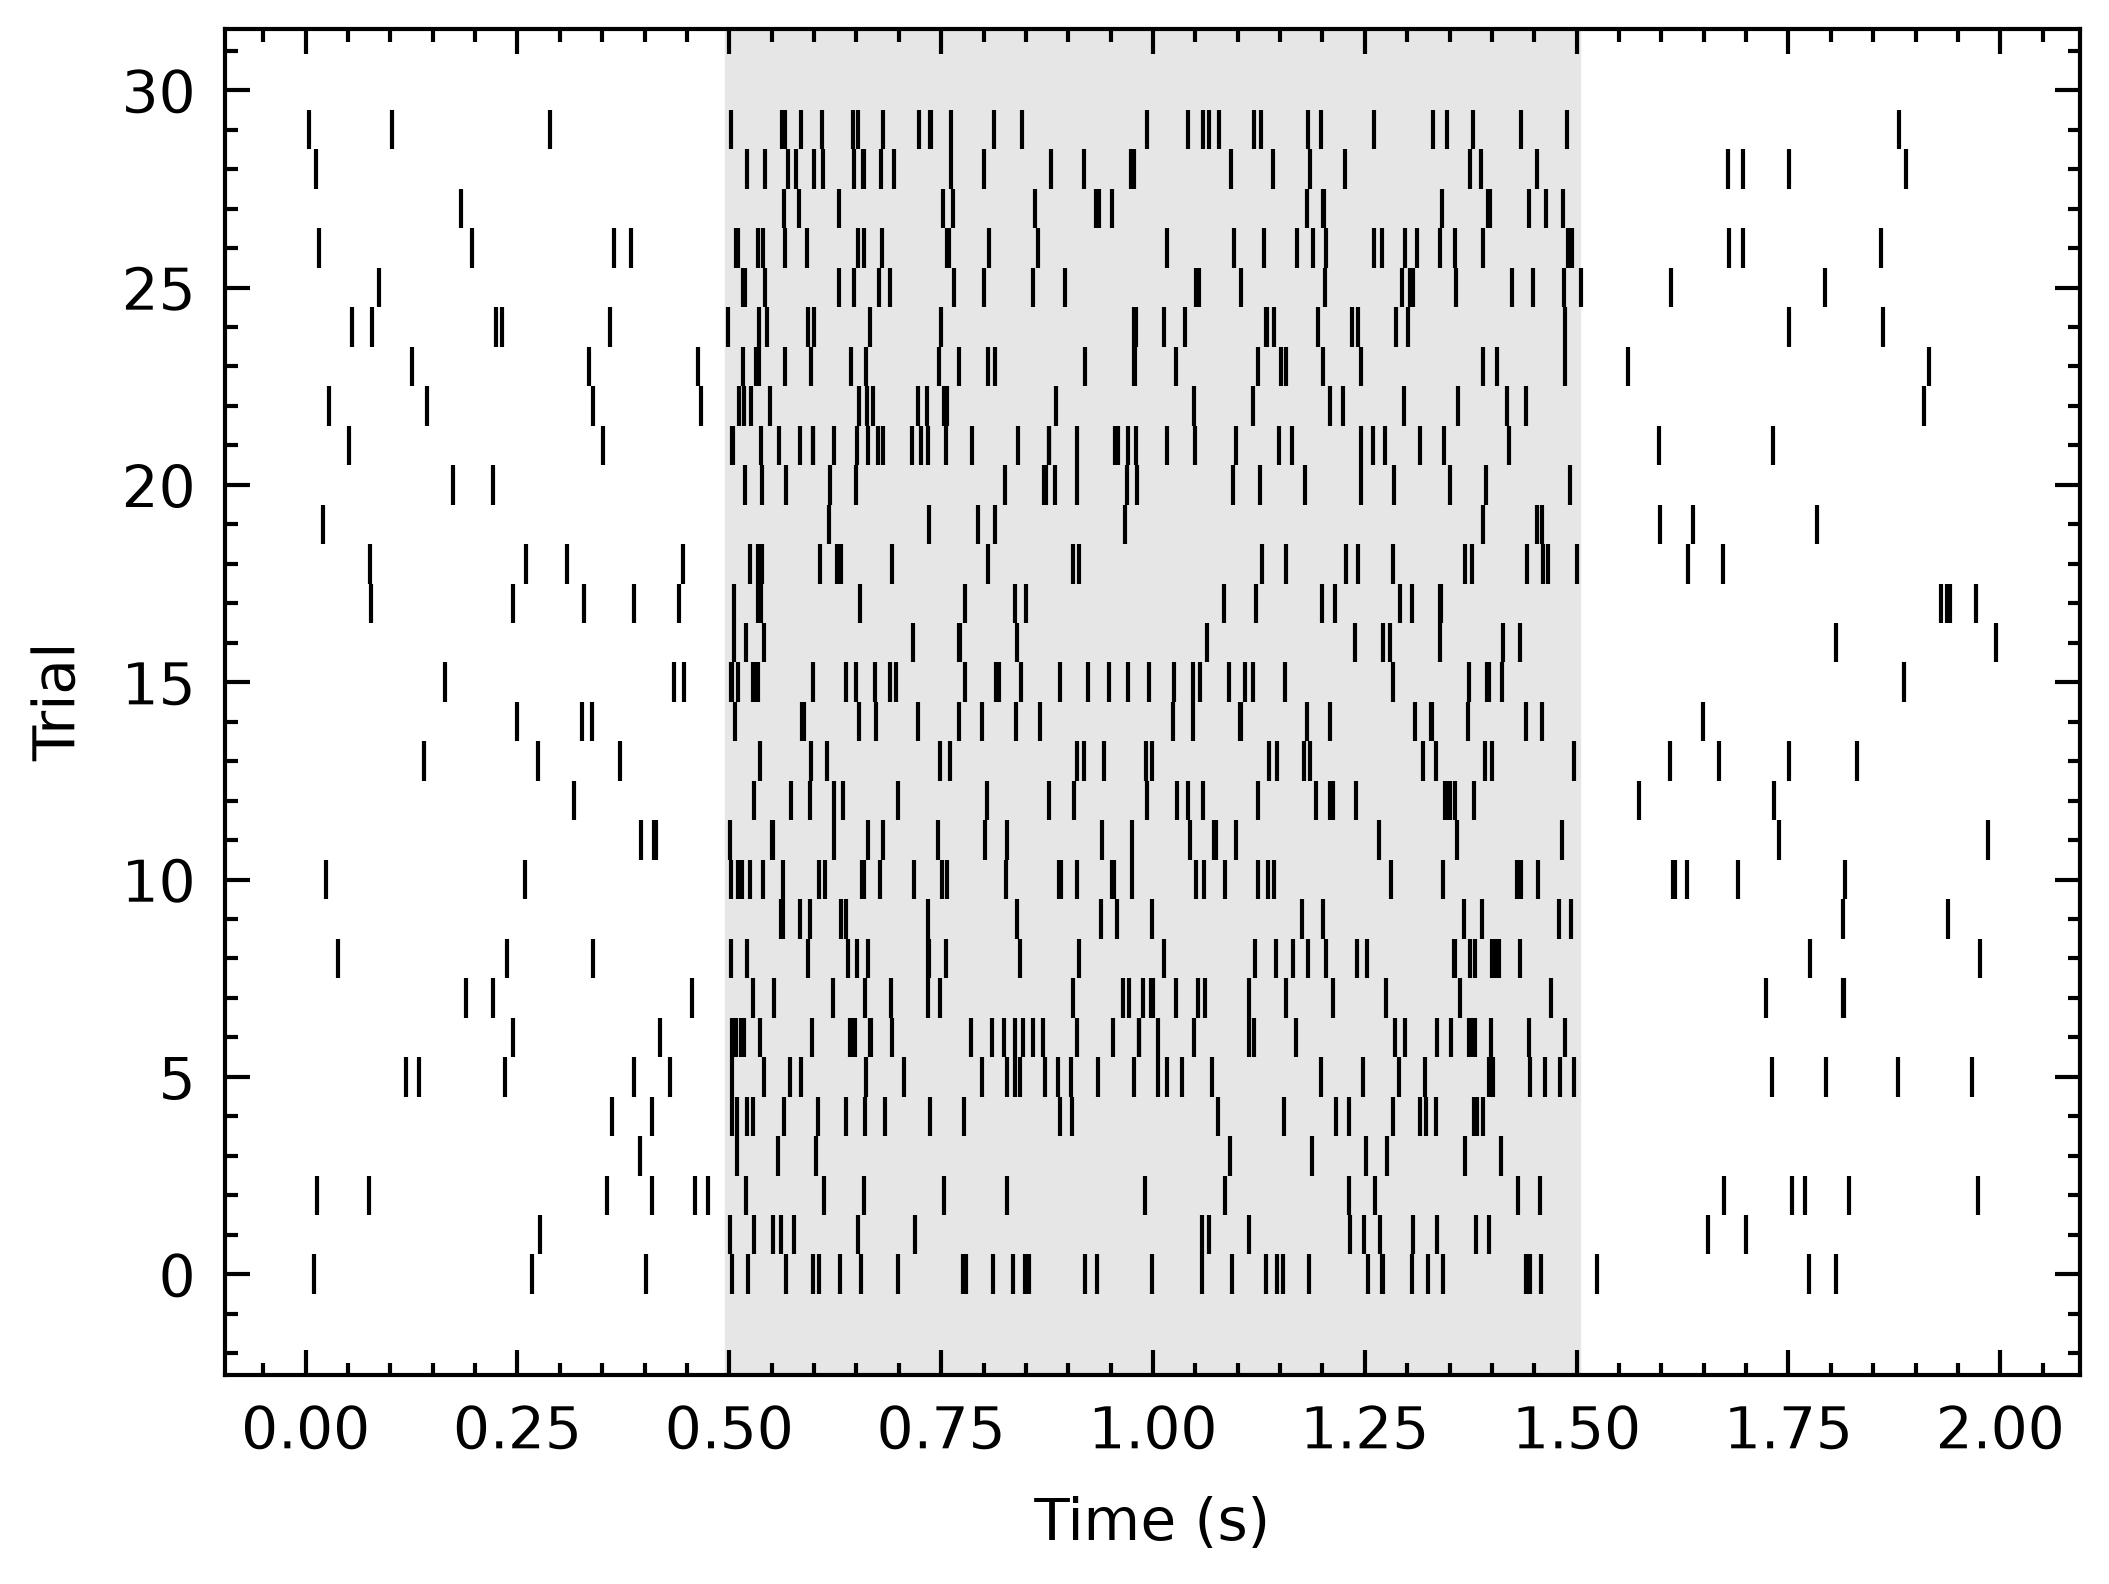

In [45]:
trials = neurodata.spike_trains(n_trials=30)

fig, ax = plt.subplots()
ax.eventplot(trials, colors="black", linewidths=0.5)
ax.axvspan(0.5, 1.5, color="0.9", zorder=0)
ax.set(xlabel="Time (s)", ylabel="Trial")
plt.show()

✏️ **Your turn**: the same neuron was also recorded after a drug:

```python
drug_trials = neurodata.spike_trains(n_trials=30, peak_rate=30, sustained_rate=12, seed=1)
```

Plot the two rasters side by side, with the titles "Control" and "Drug".
Hint: `fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, figsize=(5, 2.5))`

In [46]:
drug_trials = neurodata.spike_trains(n_trials=30, peak_rate=30, sustained_rate=12, seed=1)

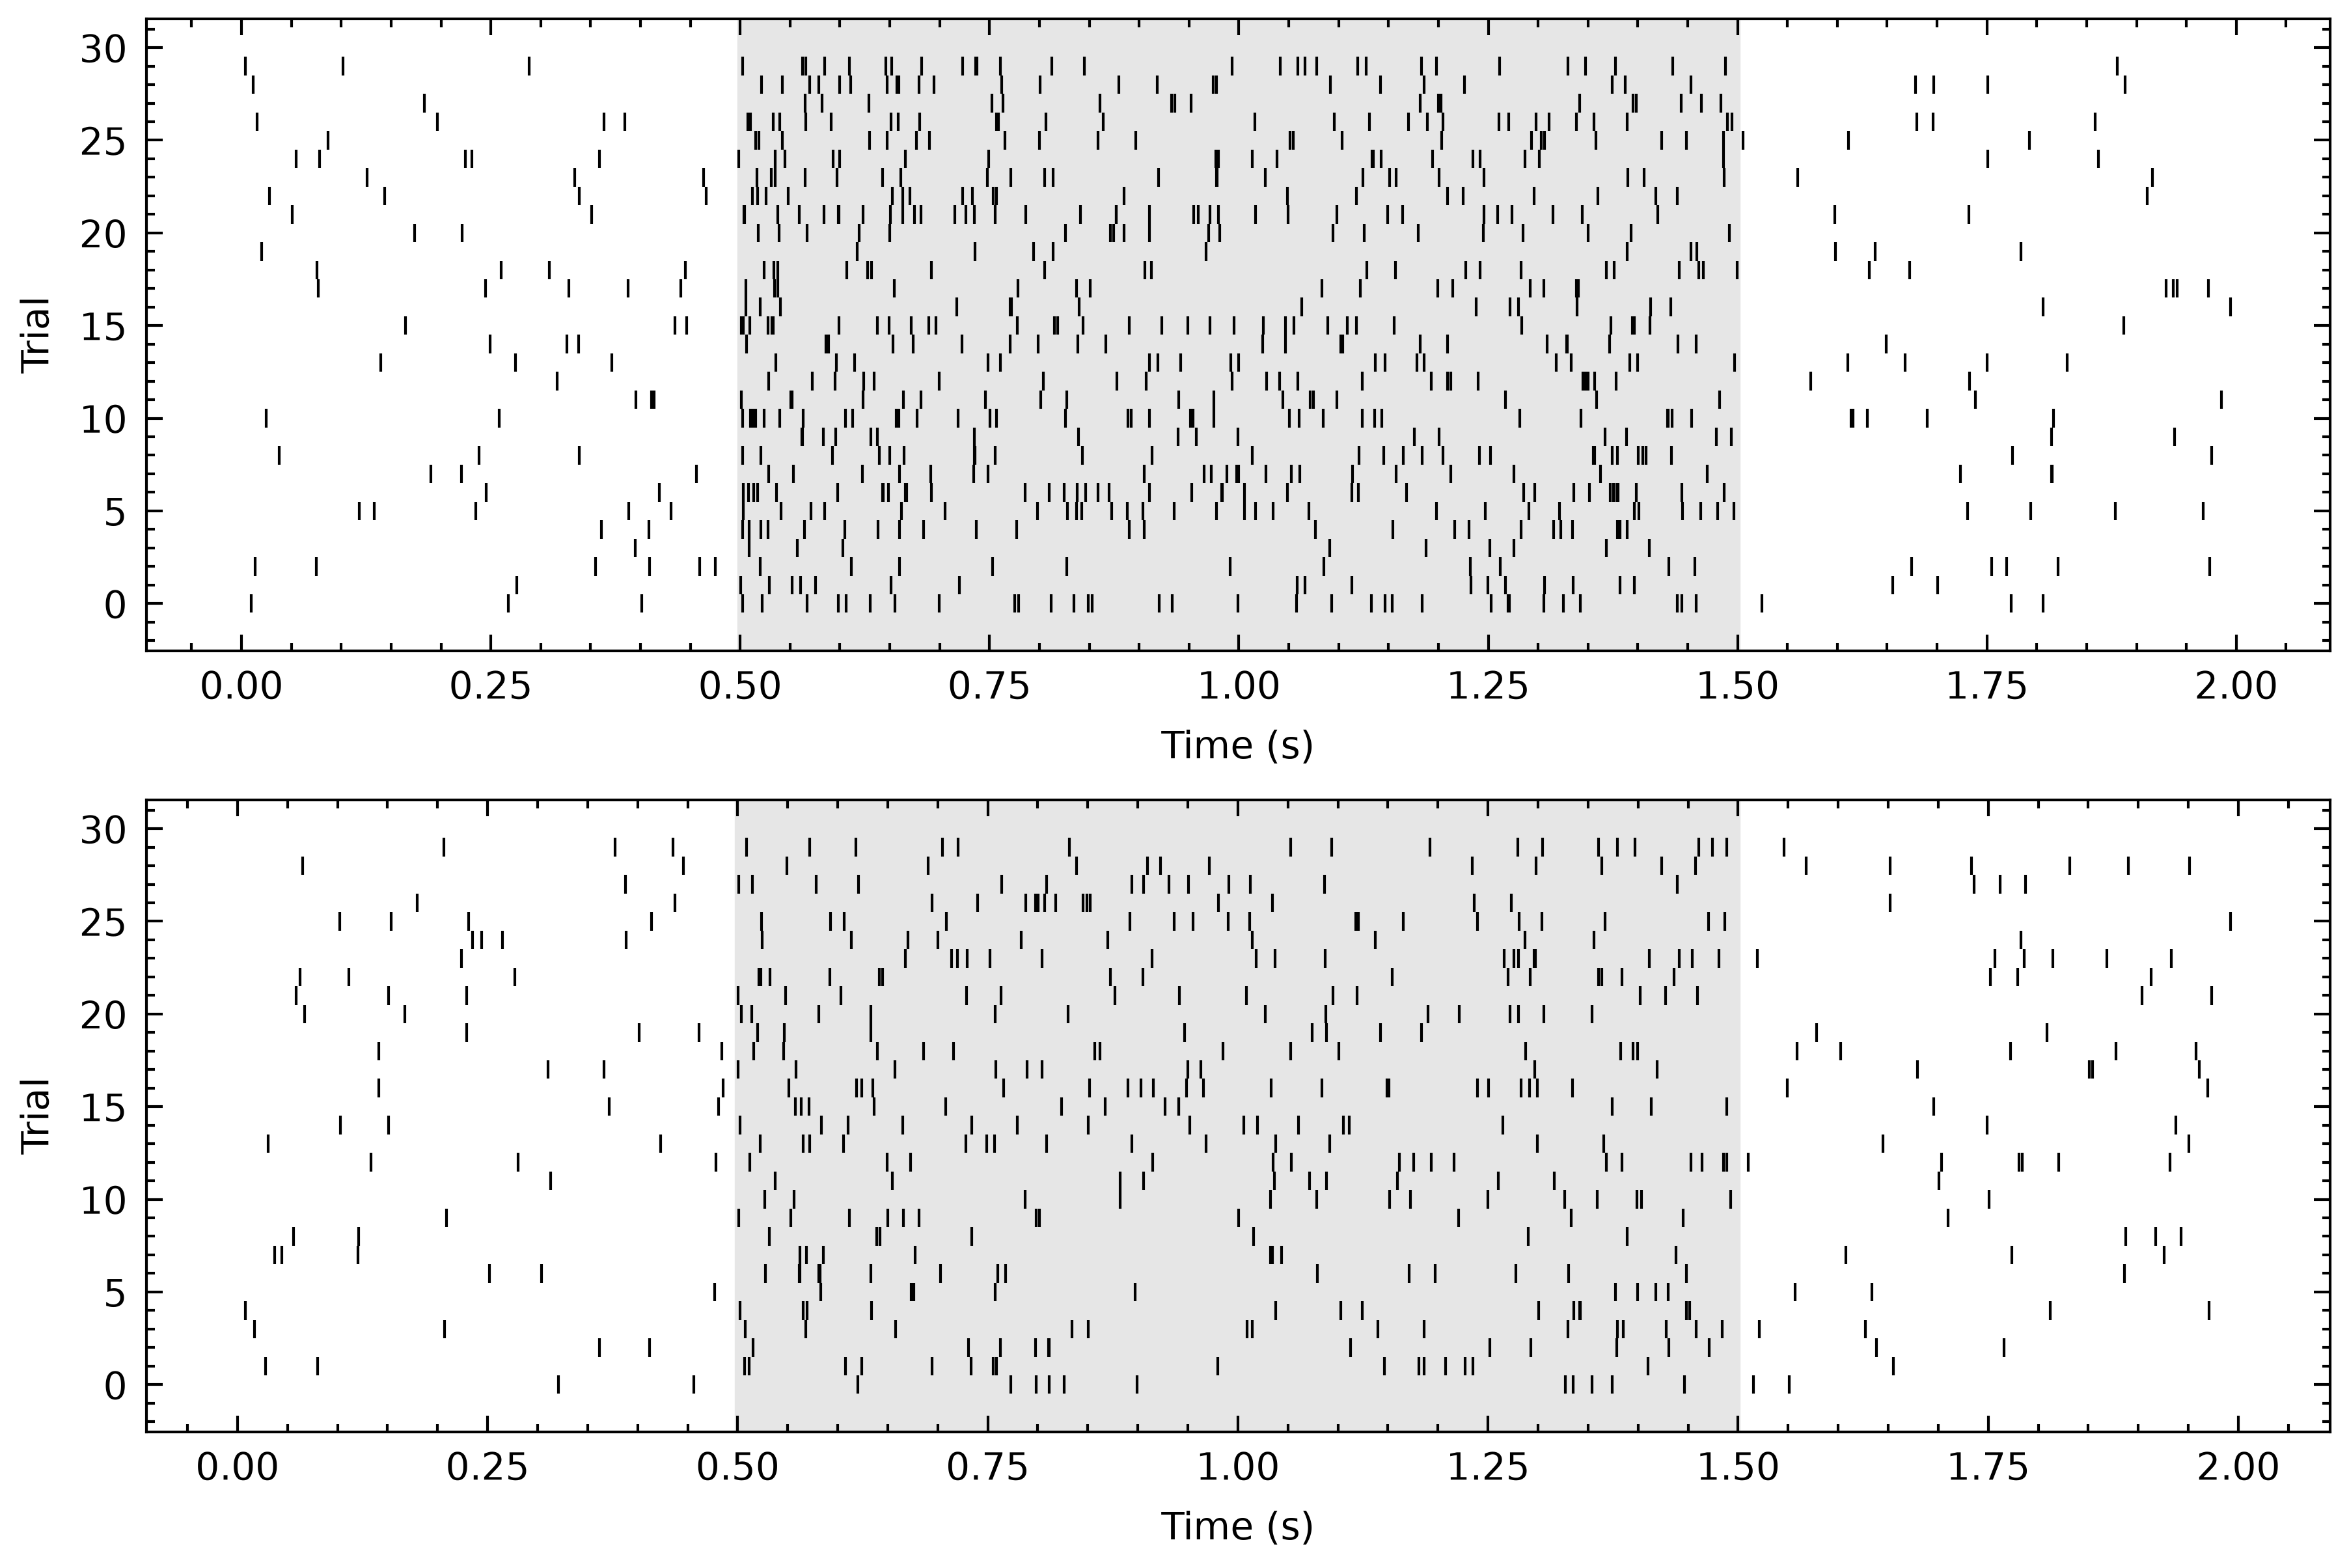

## 3. 🎛 PSTH

The peri-stimulus time histogram: spike counts in time bins, over all trials, converted to Hz.
How does the bin width change what you see?

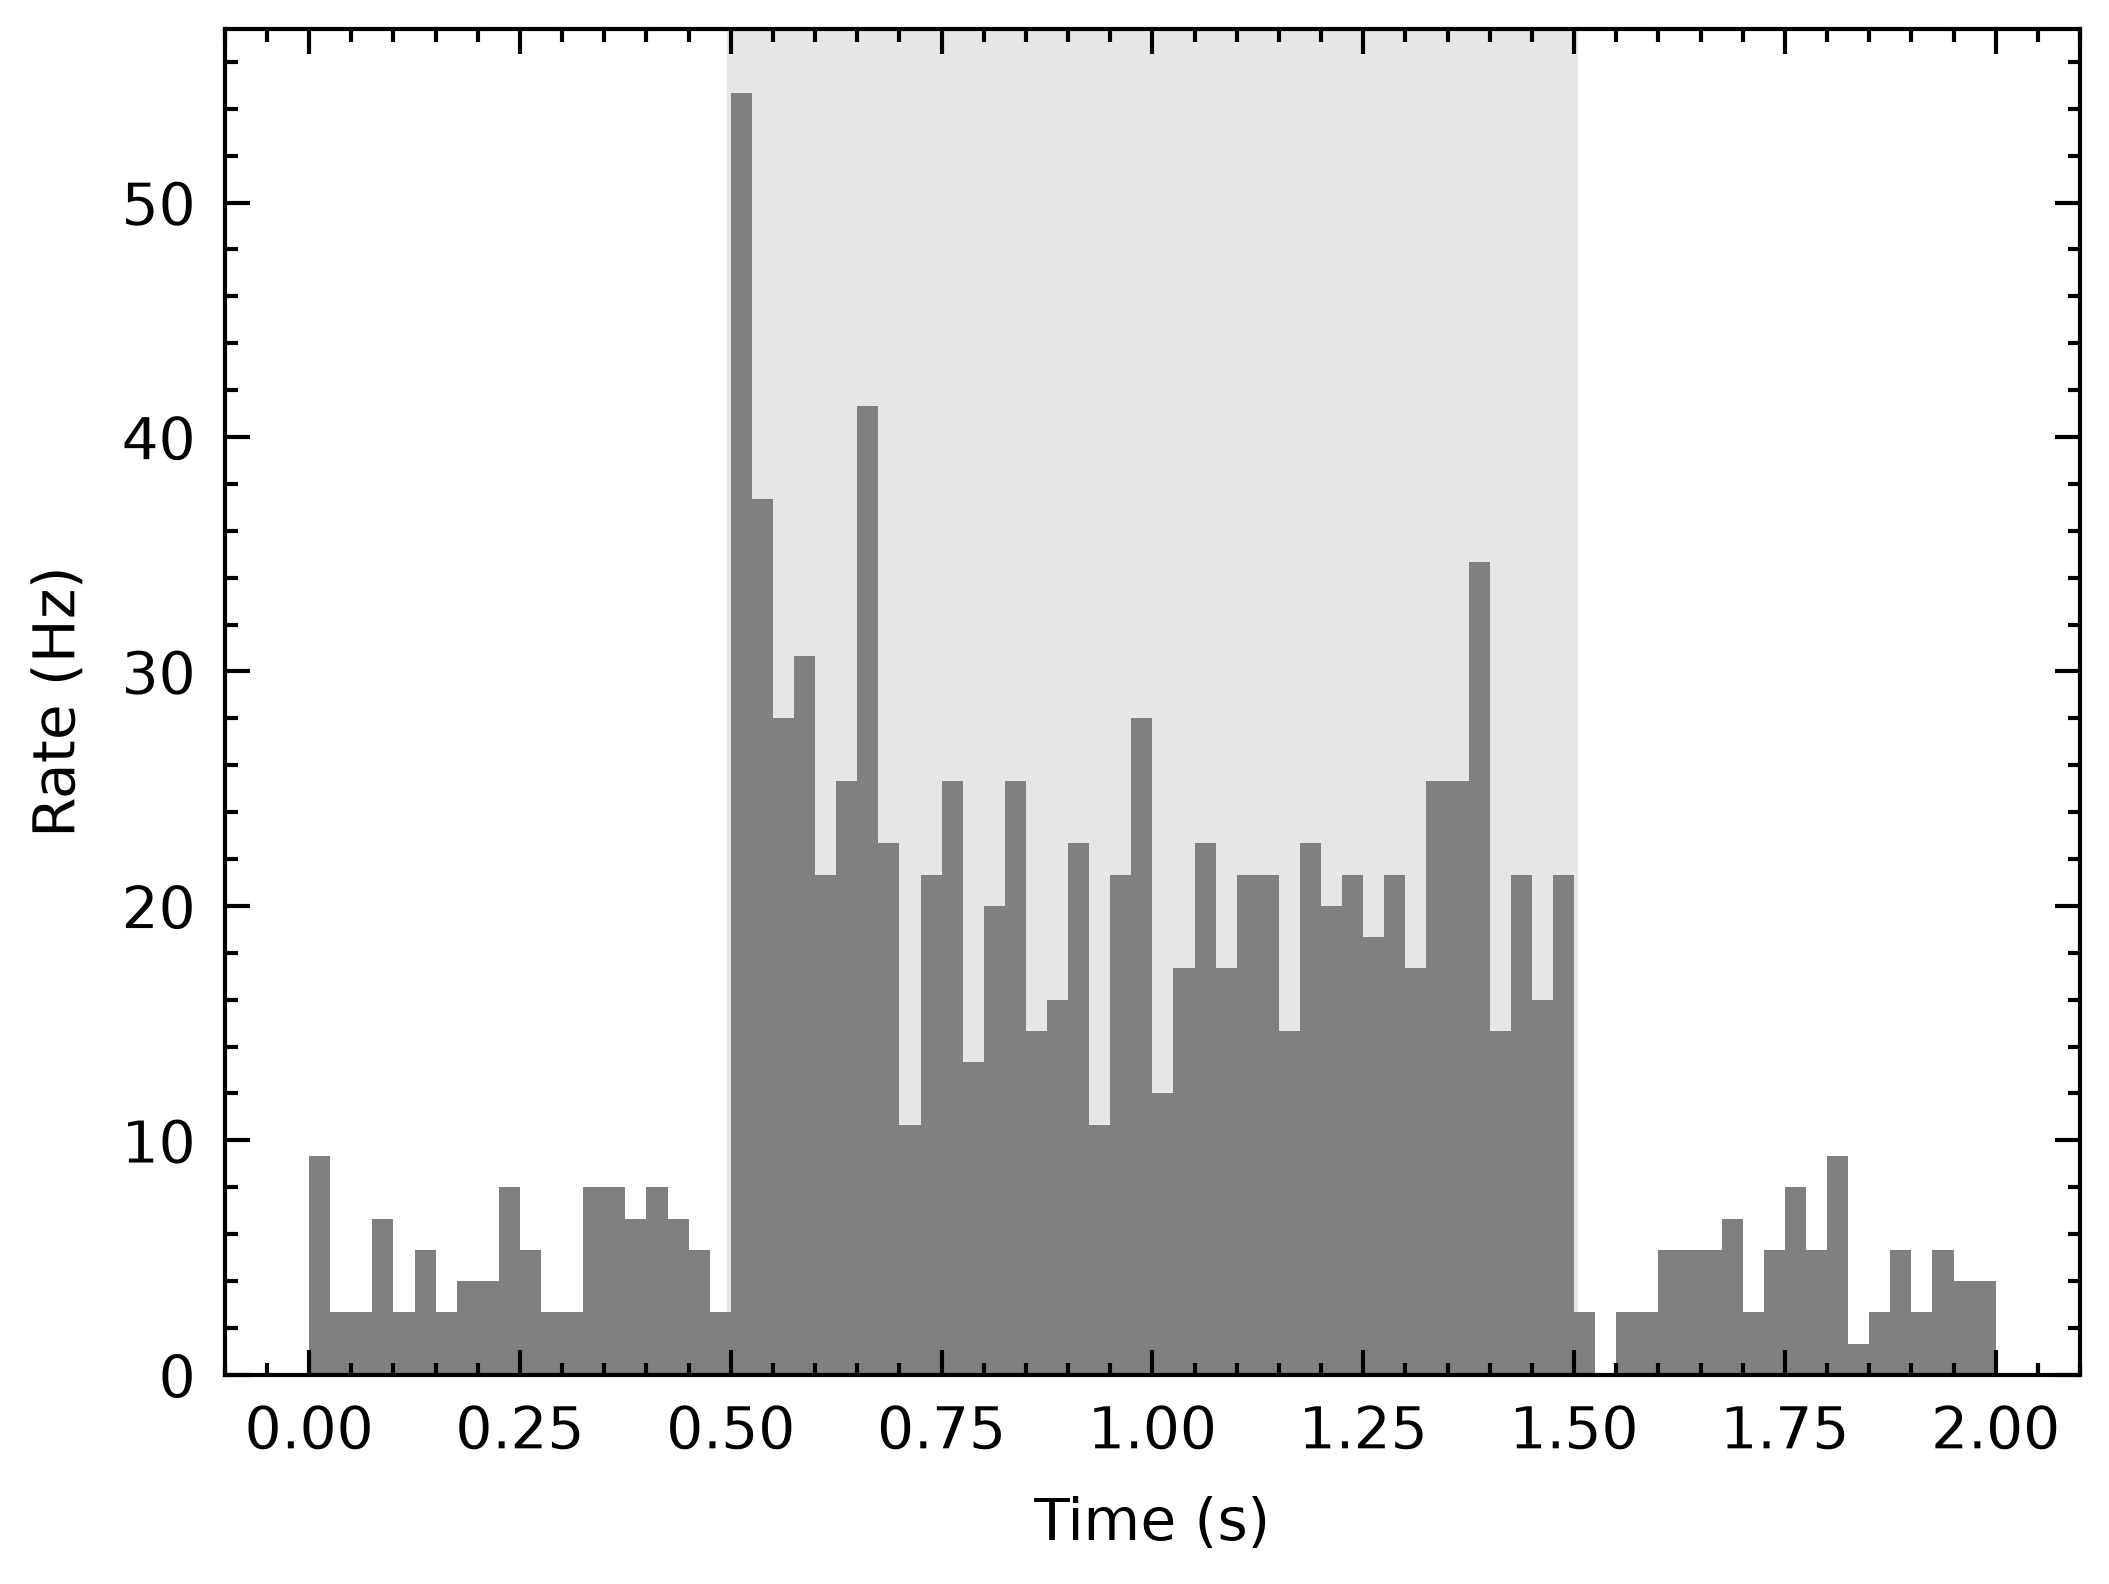

In [54]:
bin_ms = 25   # bin width in ms, try 5 to 200

width = bin_ms / 1000
edges = np.arange(0, 2 + width, width)
counts, _ = np.histogram(np.concatenate(trials), bins=edges)
rate = counts / (len(trials) * width)

fig, ax = plt.subplots()
ax.stairs(rate, edges, fill=True, color="0.5")
ax.axvspan(0.5, 1.5, color="0.9", zorder=0)
ax.set(xlabel="Time (s)", ylabel="Rate (Hz)")
plt.show()

✏️ **Your turn**: the classic figure. Put the raster **above** the PSTH, sharing the time axis
(like the membrane potential in section 1). Bonus: add the drug PSTH as a line on top
(`ax.stairs(drug_rate, edges, label="Drug")`) and a legend.

## 4. Tuning curves: mean ± SEM

`responses` has shape `(neurons, orientations, trials)`. `line, = ax.plot(...)` keeps the line, so the
shaded SEM can use the same color.

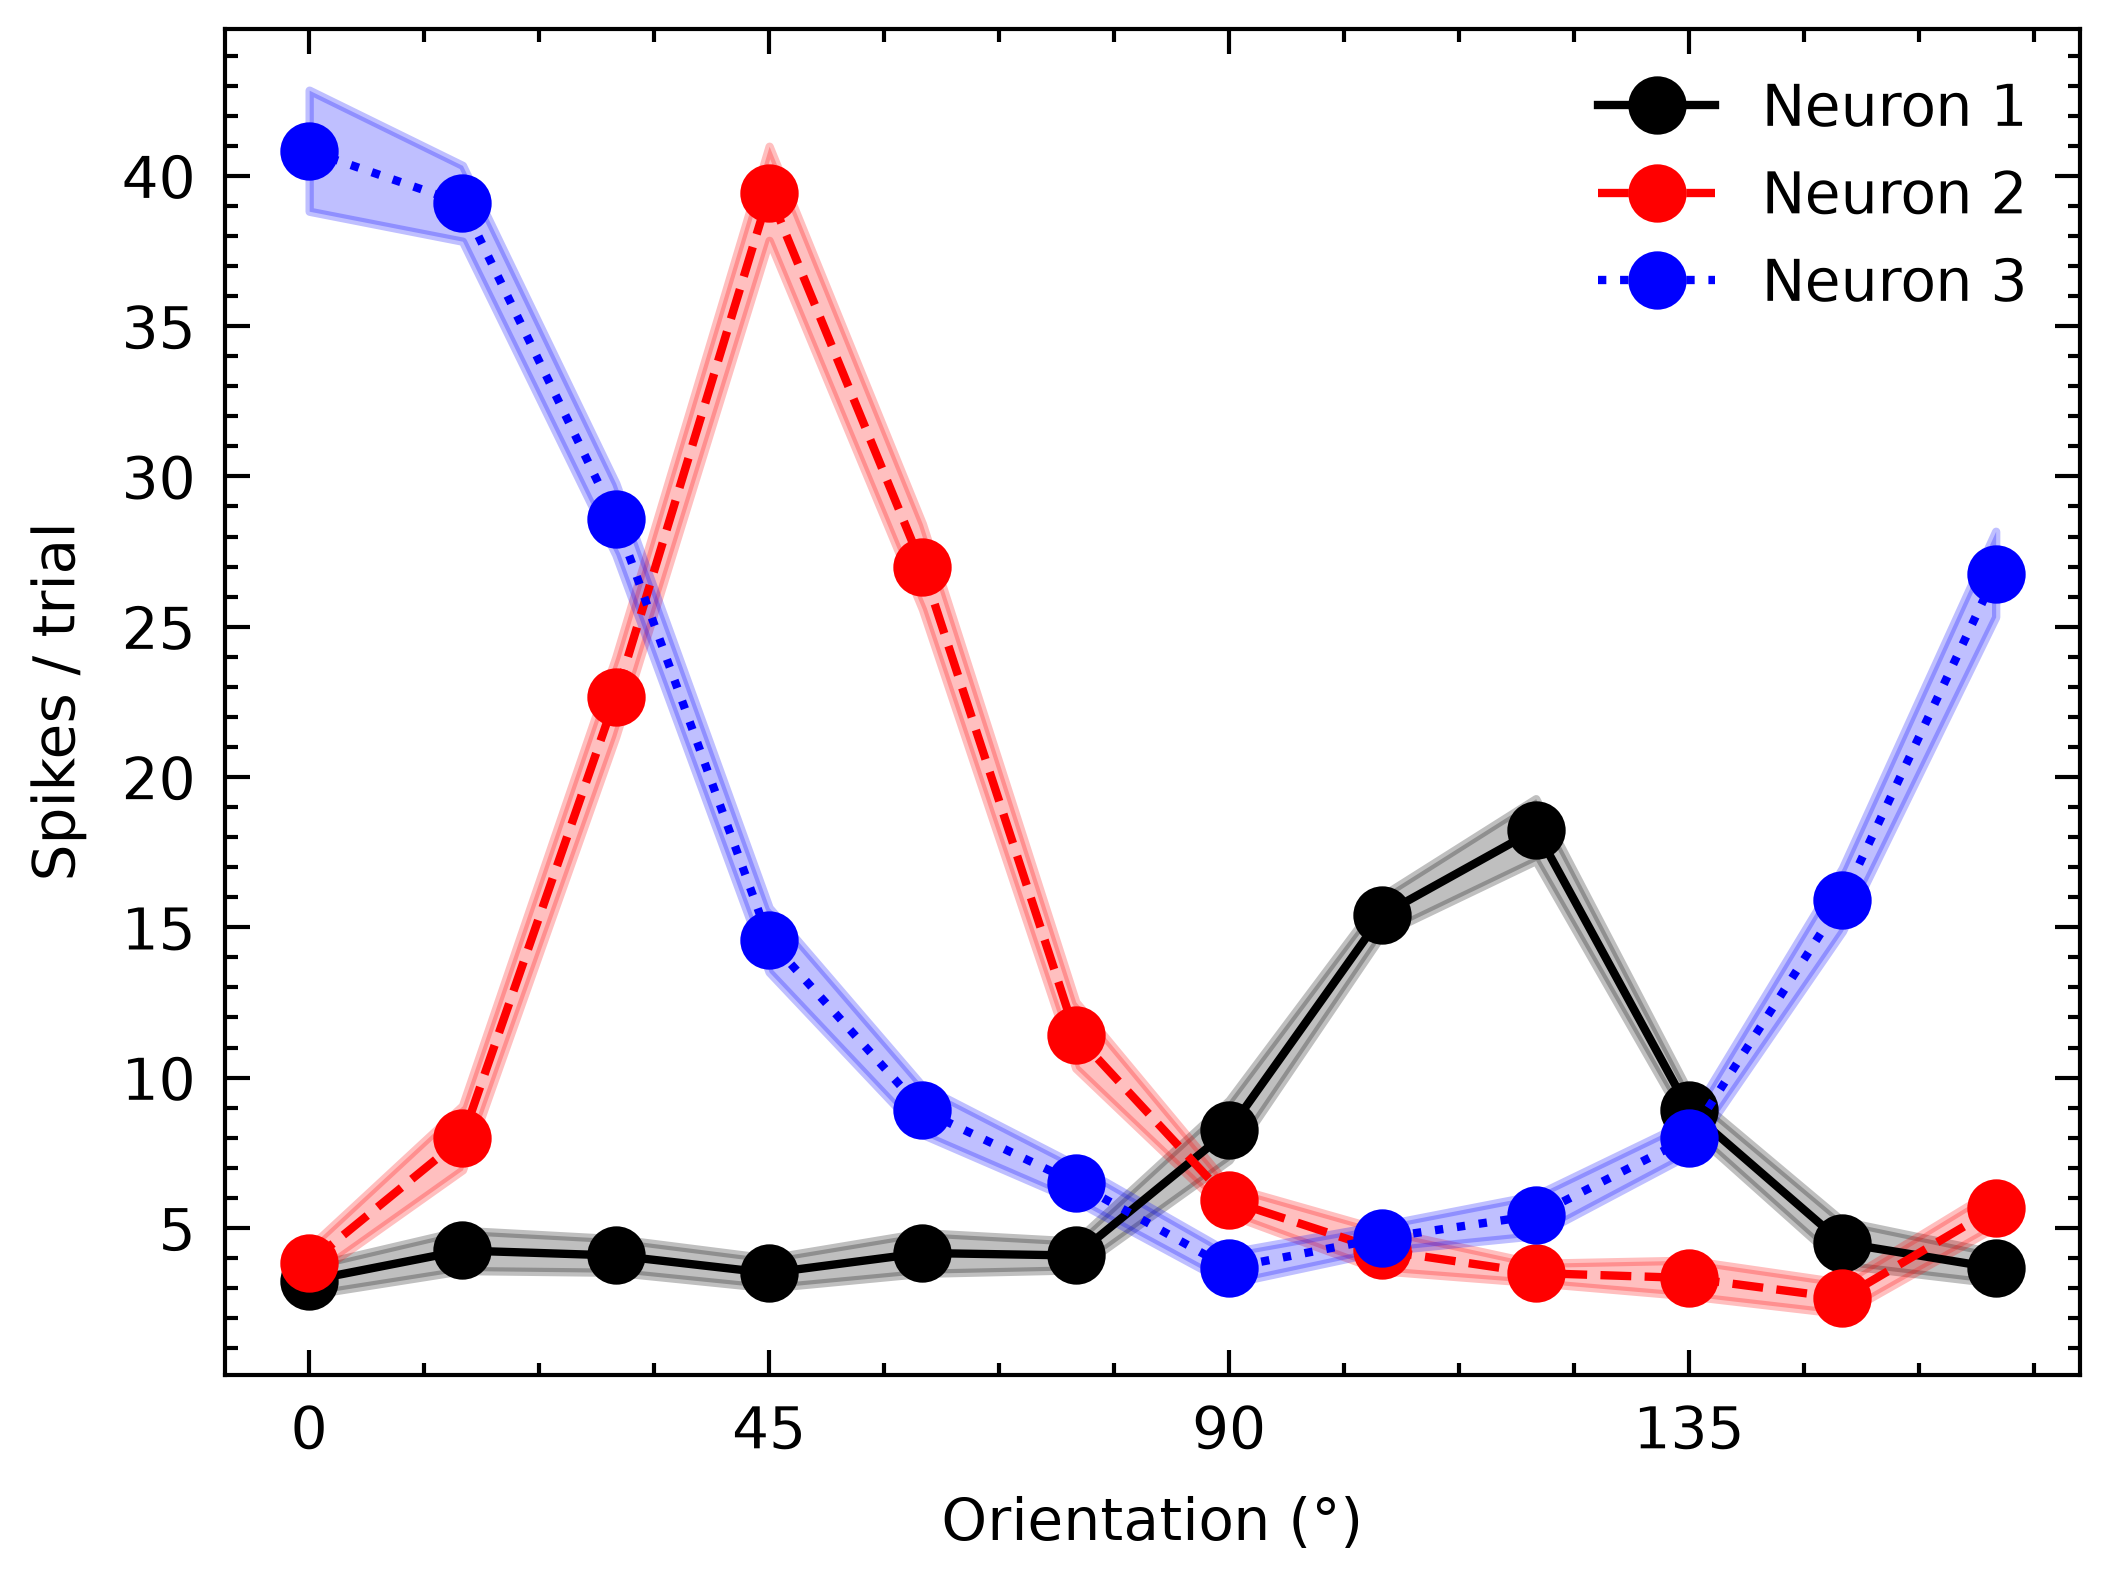

In [55]:
oris, responses = neurodata.orientation_tuning(n_neurons=3)
mean = responses.mean(axis=2)
sem = responses.std(axis=2) / np.sqrt(responses.shape[2])

fig, ax = plt.subplots()
for i in range(3):
    line, = ax.plot(oris, mean[i], marker="o", label=f"Neuron {i + 1}")
    ax.fill_between(oris, mean[i] - sem[i], mean[i] + sem[i], color=line.get_color(), alpha=0.25)
ax.set(xlabel="Orientation (°)", ylabel="Spikes / trial", xticks=[0, 45, 90, 135])
ax.legend()
plt.show()

✏️ **Your turn**
1. Mark each neuron's **preferred orientation** (the one with the highest mean) with a vertical dotted line
   in the neuron's color. Hint: `oris[np.argmax(mean[i])]` and `ax.axvline(x, color=line.get_color(), linestyle=":")`
2. Show the SEM as error bars instead of a shaded area: `ax.errorbar(oris, mean[i], yerr=sem[i], ...)`

**Colors everyone can see:** about 1 in 12 men can't tell red from green well. Use a color-blind-safe palette
(Okabe–Ito, in the options of your style file) or, like your style, give every line its own line style too.
Give each condition one color and use it in **every** figure.

## 5. 🎛 Calcium imaging heatmap

`ax.imshow` draws a 2-D array (neurons × time) as an image. Try:
* `square_pixels = True`: that's the default, and why heatmaps often come out as a thin strip
* **colormaps**: does `jet` show structure that isn't there? (Hint: look for sharp "edges" between colors.)
* **vmax**: clip the brightest frames so the rest becomes visible

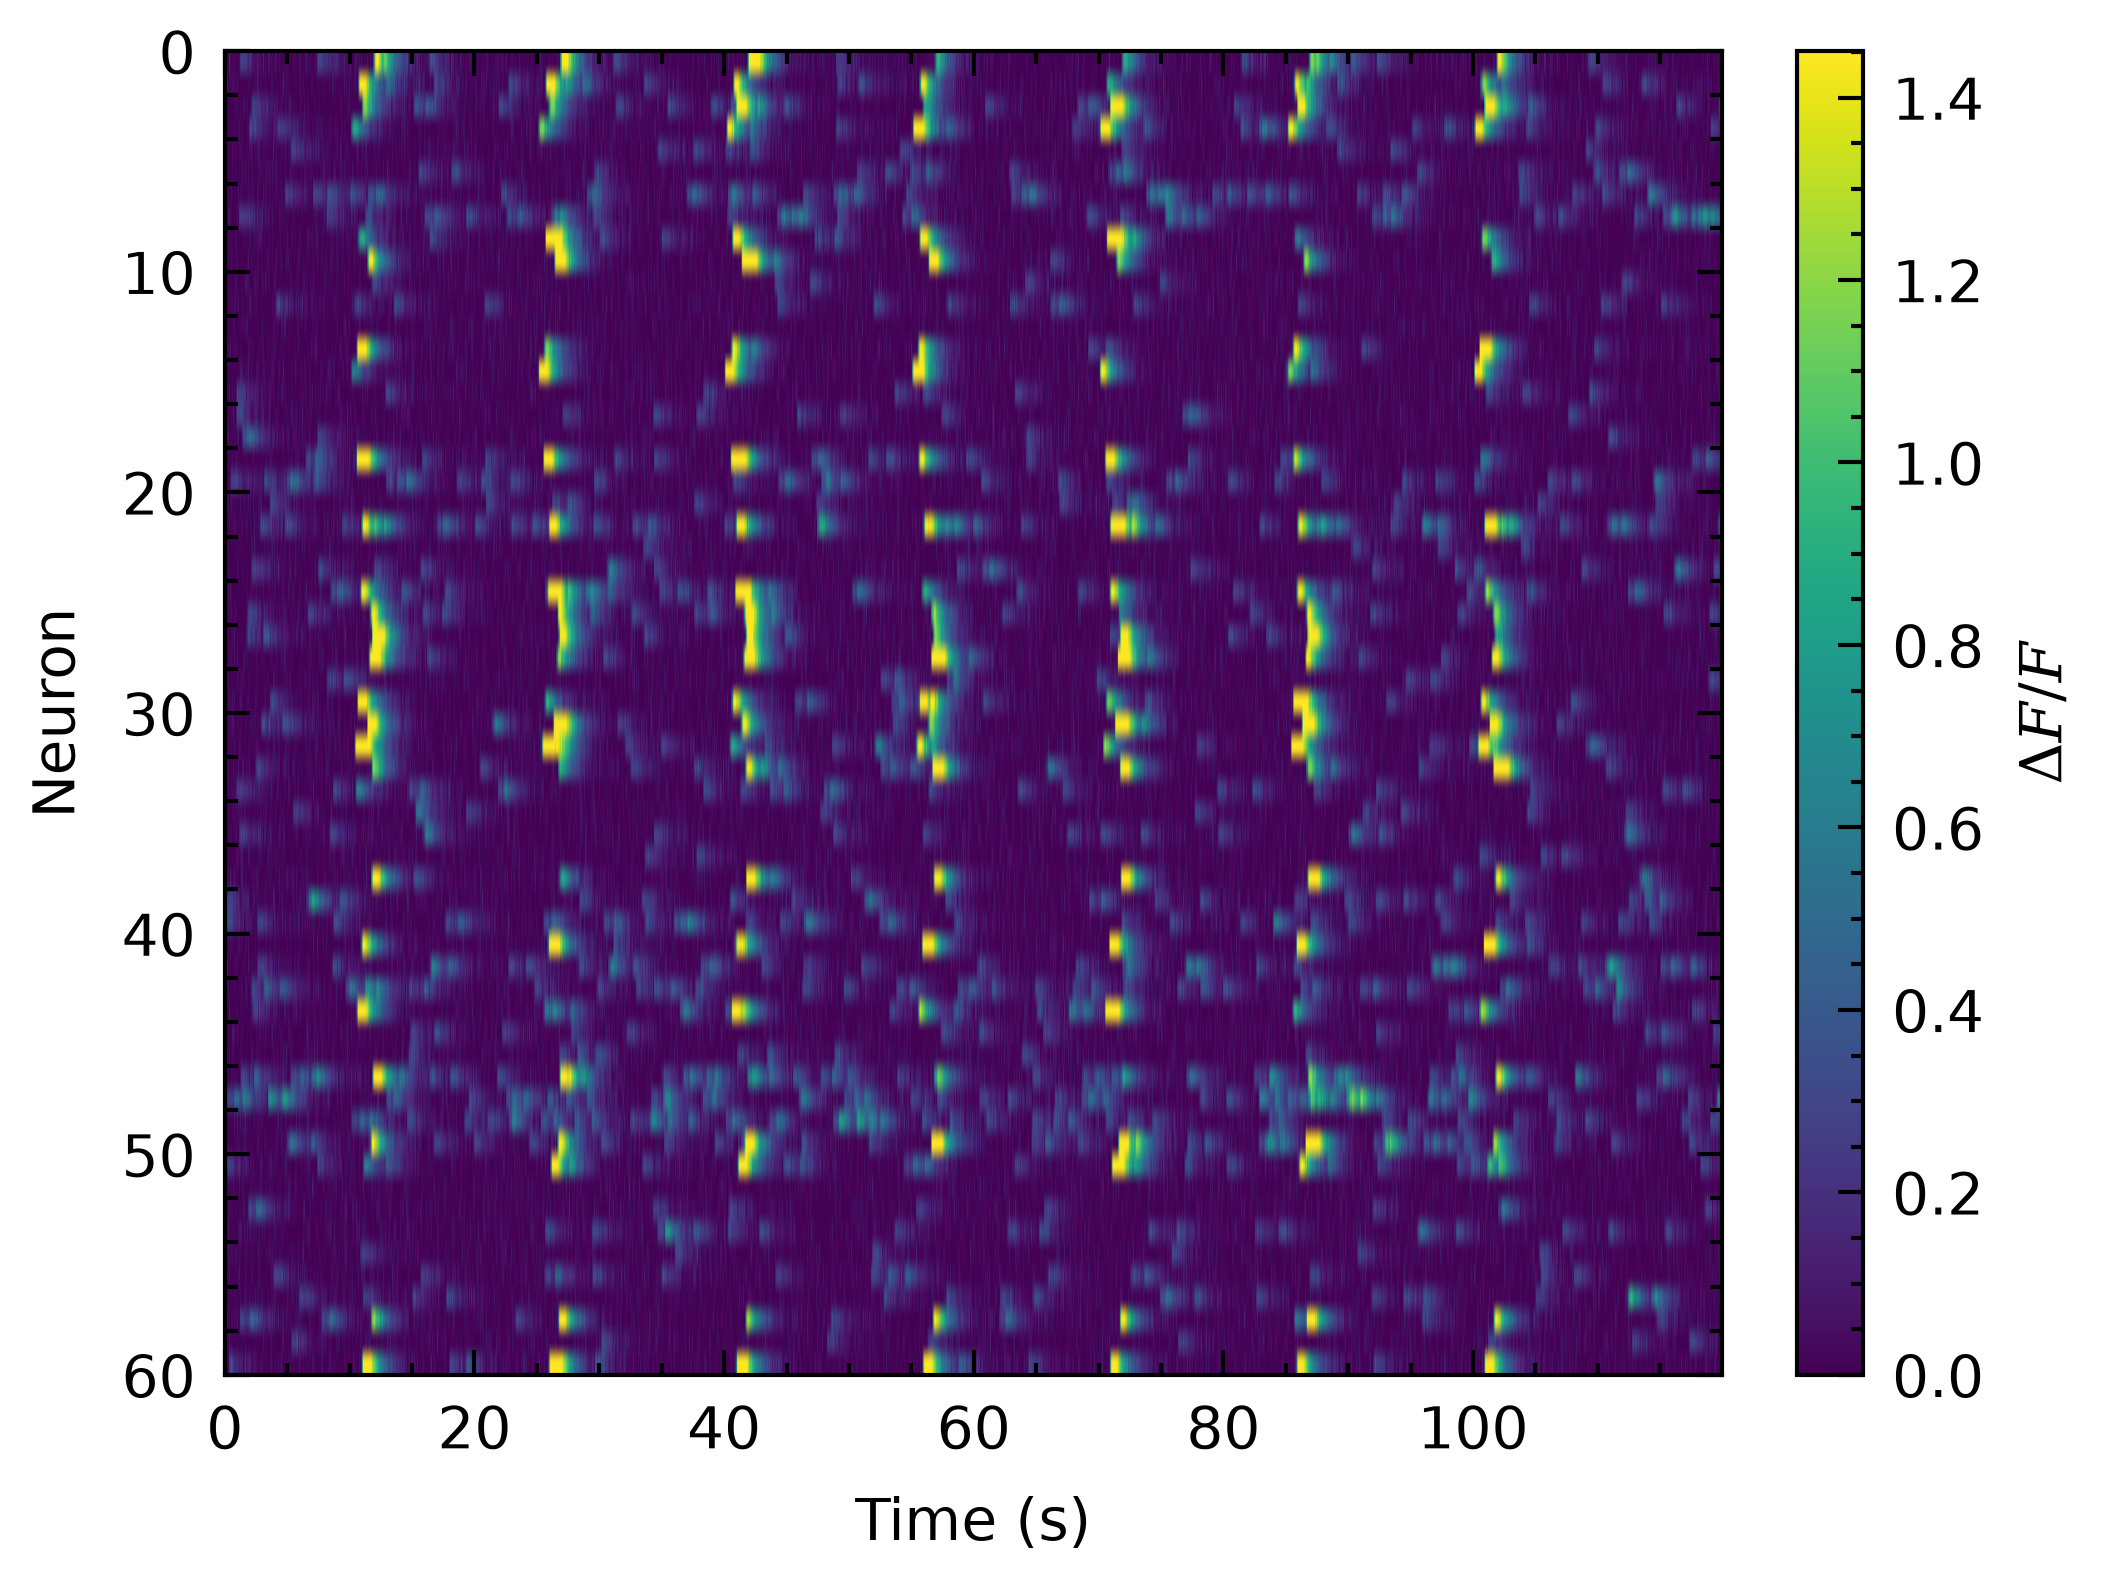

In [56]:
t_ca, dff, stim_times = neurodata.calcium_imaging()

cmap = "viridis"         # "viridis", "magma", "gray" or "jet"
vmax_percentile = 99.0   # try 90 to 100
square_pixels = False    # True or False

fig, ax = plt.subplots()
im = ax.imshow(dff, cmap=cmap, aspect="equal" if square_pixels else "auto",
               vmin=0, vmax=np.percentile(dff, vmax_percentile), extent=[0, t_ca[-1], len(dff), 0])
fig.colorbar(im, ax=ax, label=r"$\Delta F/F$")
ax.set(xlabel="Time (s)", ylabel="Neuron")
plt.show()

Our eyes read **lightness** as "more". `jet` goes light-dark-light, which invents edges; `viridis` and
`magma` get steadily lighter. Rule of thumb:

| Data | Colormap |
|---|---|
| low → high (rate, ΔF/F) | `viridis`, `magma` |
| has a zero (correlation, change) | `RdBu_r`, with `vmin=-x, vmax=x` |
| wraps around (orientation, phase) | `twilight` |

Typing `aspect="auto"` and `cmap=...` every time? Put `image.aspect: auto` and `image.cmap: magma` in
`my_style.mplstyle`.

✏️ **Your turn**
1. The neurons are in random order. Sort them so the strongest responders are at the top:
   `order = np.argsort(dff.max(axis=1))[::-1]`, then plot `dff[order]`.
2. Mark every stimulus with a thin white vertical line: `for s in stim_times: ax.axvline(s, ...)`
3. Bonus: below the heatmap, plot the 5 strongest neurons as stacked traces, each shifted up:
   `ax.plot(t_ca, dff[i] + 3 * k)`.

## 6. LFP and power spectrum

A local field potential has slow (theta, ~8 Hz) and fast (gamma, ~40 Hz) rhythms. Power spectra go on
**log–log** axes; `scipy.signal.welch` estimates the spectrum. `width_ratios` makes the left panel wider.

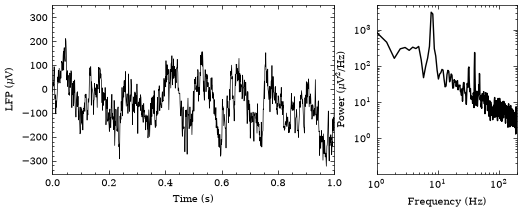

In [7]:
from scipy import signal

t_lfp, x_lfp = neurodata.lfp()
freqs, power = signal.welch(x_lfp, fs=1000, nperseg=2048)

fig, (ax_t, ax_f) = plt.subplots(1, 2, figsize=(6, 2.2), width_ratios=[2, 1])
ax_t.plot(t_lfp, x_lfp, linewidth=0.5)
ax_t.set(xlim=(0, 1), xlabel="Time (s)", ylabel=r"LFP ($\mu$V)")
ax_f.loglog(freqs[1:], power[1:])
ax_f.set(xlim=(1, 200), xlabel="Frequency (Hz)", ylabel=r"Power ($\mu$V$^2$/Hz)")
plt.show()

✏️ **Your turn**: shade the theta band (6–10 Hz) and the gamma band (30–50 Hz) in the spectrum with
`ax_f.axvspan(low, high, color="0.9", zorder=0)`, and label them with `ax_f.text(x, y, "θ")`.
Can you find the two peaks?

## 7. Show every animal

Bar plots hide the data ([Weissgerber et al., 2015](https://doi.org/10.1371/journal.pbio.1002128)).
With few animals, show every point and connect paired measurements:

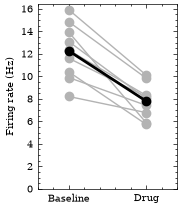

In [8]:
baseline, drug = neurodata.drug_experiment(n_animals=10)

fig, ax = plt.subplots(figsize=(1.8, 2.4))
ax.plot([0, 1], [baseline, drug], color="0.7", linestyle="-", marker="o")
ax.plot([0, 1], [baseline.mean(), drug.mean()], color="black", marker="o", linewidth=2)
ax.set_xticks([0, 1], ["Baseline", "Drug"])
ax.set(xlim=(-0.4, 1.4), ylim=(0, None), ylabel="Firing rate (Hz)")
plt.show()

With more data, a box plot. Its look (median color, outliers, filled boxes) comes from the `boxplot.*`
lines in your style file.

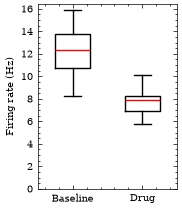

In [9]:
fig, ax = plt.subplots(figsize=(1.8, 2.4))
ax.boxplot([baseline, drug], widths=0.5)
ax.set_xticks([1, 2], ["Baseline", "Drug"])
ax.set(ylim=(0, None), ylabel="Firing rate (Hz)")
plt.show()

✏️ **Your turn**: draw every animal on top of the box plot. Points at exactly x = 1 and x = 2 would hide
each other, so shift each one sideways by a small random amount ("jitter"):

```python
rng = np.random.default_rng(0)
x = 1 + rng.uniform(-0.12, 0.12, size=len(baseline))
```

Bonus: connect each animal's two points with a thin grey line (use the **same** jitter for both).

## 8. ✏️ Your figure

Combine four plots from this notebook into one figure and save it.
`plt.subplot_mosaic` lets you **draw the layout as text**: one letter per panel, `;` starts a new row, and a
repeated letter makes a panel bigger (try `"AAB;CDB"`). 7.2 inches = two journal columns.
Save as **PDF** for papers (sharp at any zoom) and PNG for slides.

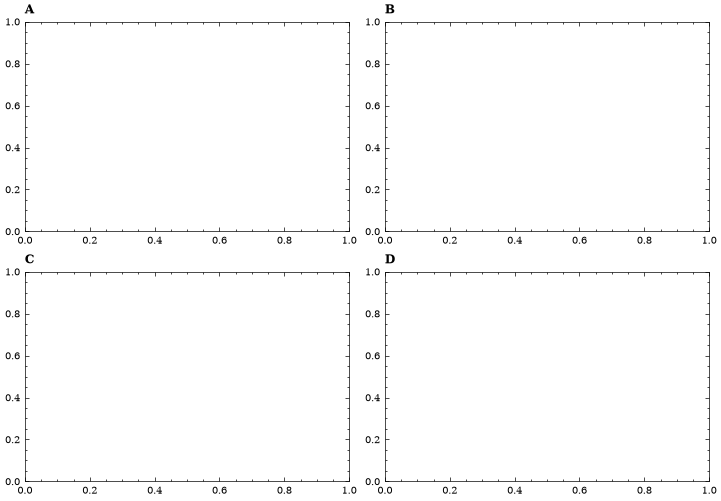

In [10]:
fig, axd = plt.subplot_mosaic("AB;CD", figsize=(7.2, 5), layout="constrained")
for name, ax in axd.items():
    ax.set_title(name, loc="left", fontweight="bold")

# Your plots here, e.g.
# axd["A"].eventplot(trials, colors="black", linewidths=0.5)

fig.savefig("my_figure.pdf")
plt.show()

## Take home

* Every new project: `plt.style.use("my_style.mplstyle")` (copy the file next to your notebook).
* Before you submit a figure:
  - [ ] made at its **final size** (1 column ≈ 3.5 in, 2 columns ≈ 7.2 in), not shrunk later
  - [ ] every axis labelled **with units**; text 5–8 pt
  - [ ] color-blind-safe colors; same condition = same color everywhere; no `jet`
  - [ ] every data point shown when *n* is small
  - [ ] saved as **PDF**

More recipes (scale bars, diverging colormaps, color-blindness check, dark slides...): `05_toolbox.ipynb`.